# Pharmaceutical Sales Dataset: Exploratory Data Analysis (EDA)
## AI-Powered Pharmacy Medicine Demand & Expiry-Risk Platform

### 1. Introduction and Clinical Context
This notebook performs exploratory data analysis on the real-world **Pharma Sales Data** dataset (2014-2019).
The dataset captures 2,106 continuous daily records aggregated across 8 major therapeutic categories classified according to the **World Health Organization (WHO) Anatomical Therapeutic Chemical (ATC)** classification system:

| ATC Code | Drug Group | Clinical Indication | Sample Medicines |
|:---|:---|:---|:---|
| **M01AB** | Acetic acid derivatives (NSAIDs) | Inflammatory joint pain, rheumatoid arthritis | Diclofenac, Aceclofenac |
| **M01AE** | Propionic acid derivatives (NSAIDs) | Pain, dysmenorrhea, fever reduction | Ibuprofen, Naproxen, Ketoprofen |
| **N02BA** | Salicylic acid and derivatives | Mild pain, cardioprotective antiplatelet | Aspirin (Acetylsalicylic acid) |
| **N02BE** | Anilides | First-line antipyretic & analgesic | Paracetamol (Acetaminophen) |
| **N05B** | Anxiolytics (Psycholeptics) | Generalized anxiety, panic disorders | Diazepam, Alprazolam, Lorazepam |
| **N05C** | Hypnotics & Sedatives | Severe insomnia management | Zolpidem, Zopiclone |
| **R03** | Obstructive airway diseases | Bronchial asthma, COPD | Salbutamol, Budesonide, Montelukast |
| **R06** | Antihistamines for systemic use | Seasonal allergies, allergic rhinitis | Cetirizine, Levocetirizine, Loratadine |


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configure visualization style
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 10

# Load authentic daily sales dataset
df = pd.read_csv('../../dataset/raw/salesdaily.csv')
df['datum'] = pd.to_datetime(df['datum'])
df = df.sort_values('datum').reset_index(drop=True)
atc_cols = ['M01AB', 'M01AE', 'N02BA', 'N02BE', 'N05B', 'N05C', 'R03', 'R06']

print(f'Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns')
print(f'Date Range: {df["datum"].min().strftime("%Y-%m-%d")} to {df["datum"].max().strftime("%Y-%m-%d")}')
df.head()

Dataset Shape: 2106 rows, 13 columns
Date Range: 2014-01-02 to 2019-10-08


,datum,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06,Year,Month,Hour,Weekday Name
0,2014-01-02,0.0,3.67,3.4,32.40,7.0,0.0,0.0,2.0,2014,1,248,Thursday
1,2014-01-03,8.0,4.00,4.4,50.60,16.0,0.0,20.0,4.0,2014,1,276,Friday
2,2014-01-04,2.0,1.00,6.5,61.85,10.0,0.0,9.0,1.0,2014,1,276,Saturday
3,2014-01-05,4.0,3.00,7.0,41.10,8.0,0.0,3.0,0.0,2014,1,276,Sunday
4,2014-01-06,5.0,1.00,4.5,21.70,16.0,2.0,6.0,2.0,2014,1,276,Monday


### 2. Missing Values, Data Types, and Zero-Sales Sparsity
A critical requirement for retail pharmaceutical forecasting is understanding zero-sales days.
- Specialized medications (e.g. hypnotics or specialized respiratory drugs) have frequent non-sales days.
- Standard percentage error metrics like **MAPE** divide by actual sales and explode when sales are zero. Therefore, **WAPE (Weighted Absolute Percentage Error)**, **MAE**, and **RMSE** must be employed.


In [2]:
# Null check & zero-sales counts
integrity_summary = pd.DataFrame({
    'Data Type': df[atc_cols].dtypes.astype(str),
    'Null Count': df[atc_cols].isnull().sum(),
    'Null %': (df[atc_cols].isnull().sum() / len(df)) * 100,
    'Zero Count': (df[atc_cols] == 0).sum(),
    'Zero %': ((df[atc_cols] == 0).sum() / len(df)) * 100
})
integrity_summary

,Data Type,Null Count,Null %,Zero Count,Zero %
M01AB,float64,0,0.0,40,1.899335
M01AE,float64,0,0.0,36,1.709402
N02BA,float64,0,0.0,78,3.703704
N02BE,float64,0,0.0,26,1.234568
N05B,float64,0,0.0,43,2.041785
N05C,float64,0,0.0,1430,67.901235
R03,float64,0,0.0,484,22.981956
R06,float64,0,0.0,256,12.155745


### 3. Comprehensive Descriptive Statistics
We calculate central tendency, dispersion, and distribution asymmetry (skewness and kurtosis) across all 8 therapeutic classes.


In [3]:
desc_stats = df[atc_cols].describe().T
desc_stats['skewness'] = df[atc_cols].skew()
desc_stats['kurtosis'] = df[atc_cols].kurt()
desc_stats['variance'] = df[atc_cols].var()
desc_stats[['mean', 'std', 'min', '25%', '50%', '75%', 'max', 'skewness', 'kurtosis']]

,mean,std,min,25%,50%,75%,max,skewness,kurtosis
M01AB,5.033683,2.737579,0.0,3.00,4.99,6.670,17.340000,0.642313,0.590035
M01AE,3.895830,2.133337,0.0,2.34,3.67,5.138,14.463000,0.718377,0.891824
N02BA,3.880441,2.384010,0.0,2.00,3.50,5.200,16.000000,0.849497,1.187551
N02BE,29.917095,15.590966,0.0,19.00,26.90,38.300,161.000000,1.202291,3.418982
N05B,8.853627,5.605605,0.0,5.00,8.00,12.000,54.833333,1.324840,4.022888
N05C,0.593522,1.092988,0.0,0.00,0.00,1.000,9.000000,2.520468,8.763072
R03,5.512262,6.428736,0.0,1.00,4.00,8.000,45.000000,1.829746,4.015505
R06,2.900198,2.415816,0.0,1.00,2.00,4.000,15.000000,1.292813,1.989410


### 4. Overall Sales Volume by Drug Class
Visualizing total units dispensed per therapeutic group over the 5.75-year span.


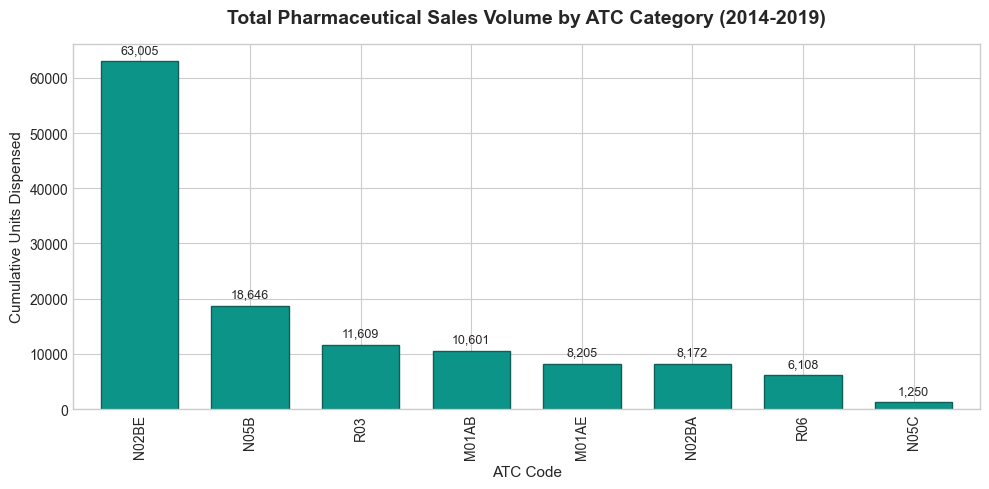

In [4]:
totals = df[atc_cols].sum().sort_values(ascending=False)
plt.figure(figsize=(10, 5))
ax = totals.plot(kind='bar', color='#0d9488', edgecolor='#115e59', width=0.7)
plt.title('Total Pharmaceutical Sales Volume by ATC Category (2014-2019)', fontsize=14, fontweight='bold', pad=15)
plt.ylabel('Cumulative Units Dispensed', fontsize=11)
plt.xlabel('ATC Code', fontsize=11)
for p in ax.patches:
    ax.annotate(f'{p.get_height():,.0f}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', xytext=(0, 4), textcoords='offset points', fontsize=9)
plt.tight_layout()
plt.show()

### 5. Multi-Year Daily Sales Trends and 30-Day Moving Averages
Visualizing daily sales fluctuations against smoothed trends to detect macro shifts and baseline velocity.


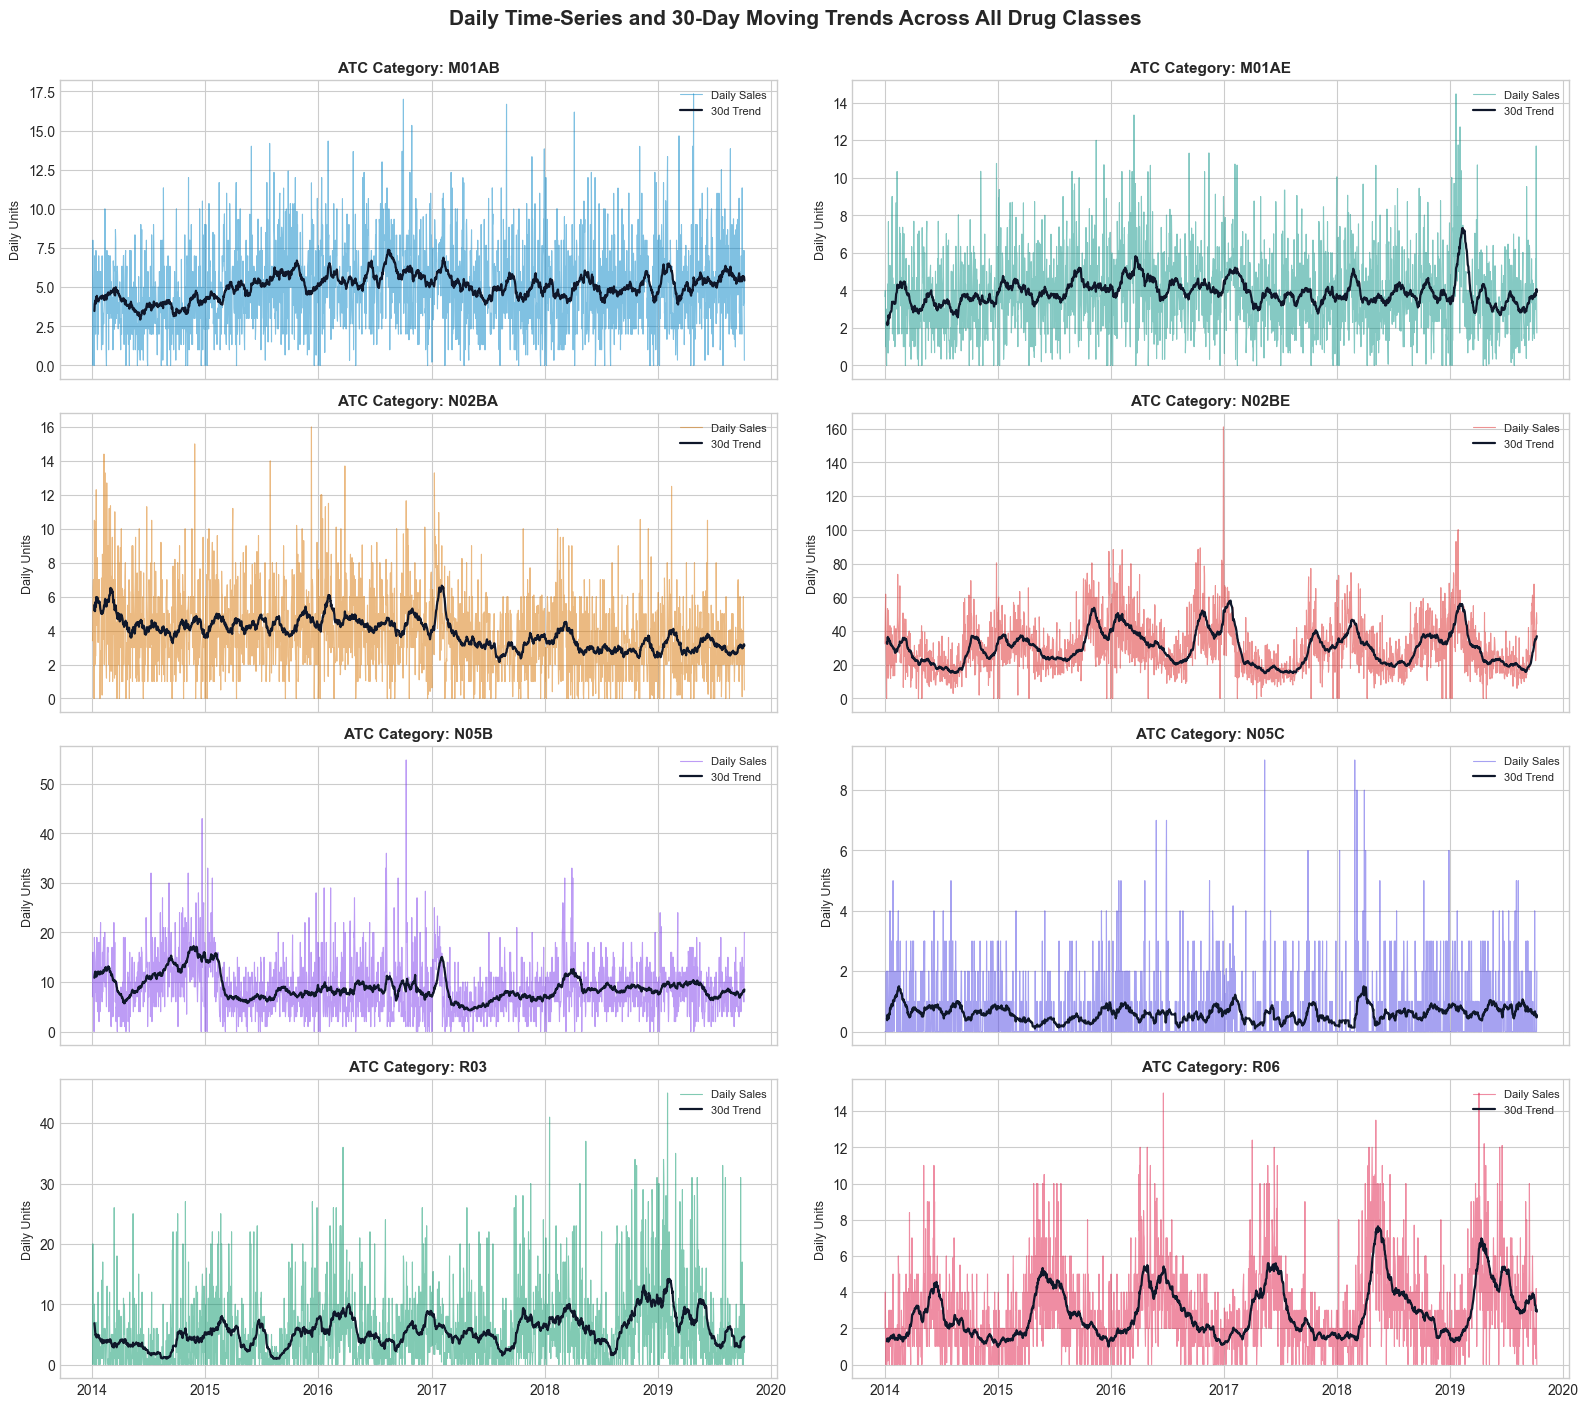

In [5]:
fig, axes = plt.subplots(4, 2, figsize=(16, 14), sharex=True)
axes = axes.flatten()
colors = ['#0284c7', '#0d9488', '#d97706', '#dc2626', '#7c3aed', '#4f46e5', '#059669', '#e11d48']
for i, col in enumerate(atc_cols):
    axes[i].plot(df['datum'], df[col], color=colors[i], alpha=0.5, linewidth=0.8, label='Daily Sales')
    axes[i].plot(df['datum'], df[col].rolling(30, min_periods=7).mean(), color='#0f172a', linewidth=1.6, label='30d Trend')
    axes[i].set_title(f'ATC Category: {col}', fontsize=11, fontweight='bold')
    axes[i].set_ylabel('Daily Units', fontsize=9)
    axes[i].legend(loc='upper right', fontsize=8)
fig.suptitle('Daily Time-Series and 30-Day Moving Trends Across All Drug Classes', fontsize=15, fontweight='bold', y=1.002)
plt.tight_layout()
plt.show()

### 6. Seasonality Patterns: Weekly and Monthly Cycles
Examining how pharmacy footfall and prescription cycles vary by day of week and month of year.


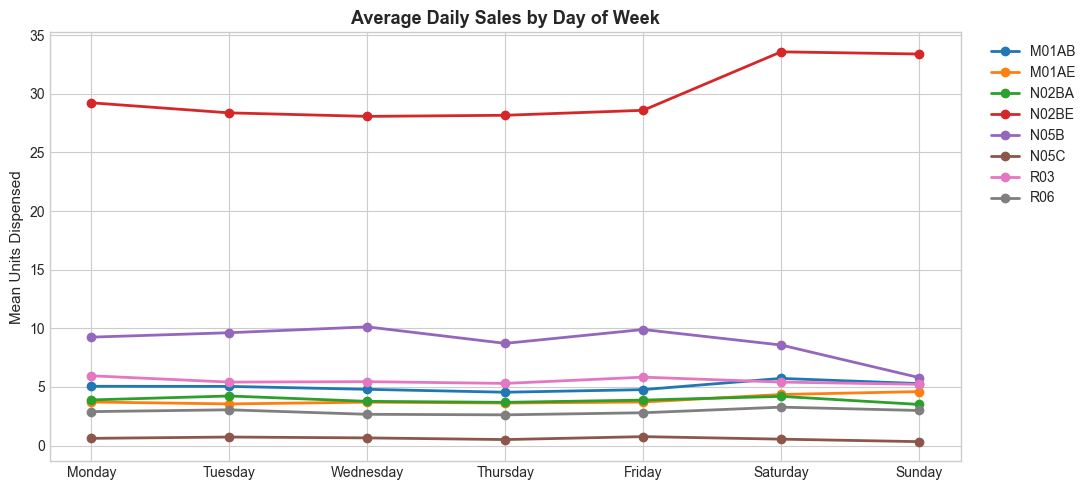

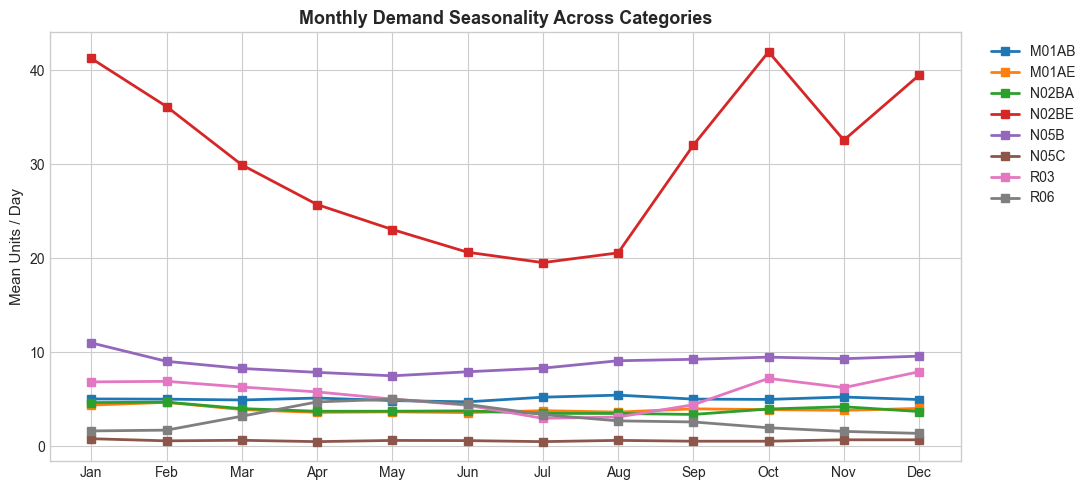

In [6]:
df['day_name'] = df['datum'].dt.day_name()
order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
dow_avg = df.groupby('day_name')[atc_cols].mean().reindex(order)

plt.figure(figsize=(11, 5))
for col in atc_cols:
    plt.plot(dow_avg.index, dow_avg[col], marker='o', label=col, linewidth=2)
plt.title('Average Daily Sales by Day of Week', fontsize=13, fontweight='bold')
plt.ylabel('Mean Units Dispensed', fontsize=11)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

df['month'] = df['datum'].dt.month
monthly_avg = df.groupby('month')[atc_cols].mean()
months_labels = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

plt.figure(figsize=(11, 5))
for col in atc_cols:
    plt.plot(months_labels, monthly_avg[col], marker='s', label=col, linewidth=2)
plt.title('Monthly Demand Seasonality Across Categories', fontsize=13, fontweight='bold')
plt.ylabel('Mean Units / Day', fontsize=11)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

### 7. Correlation Matrix
Correlation heatmap measuring co-dispensing relationships across the categories.


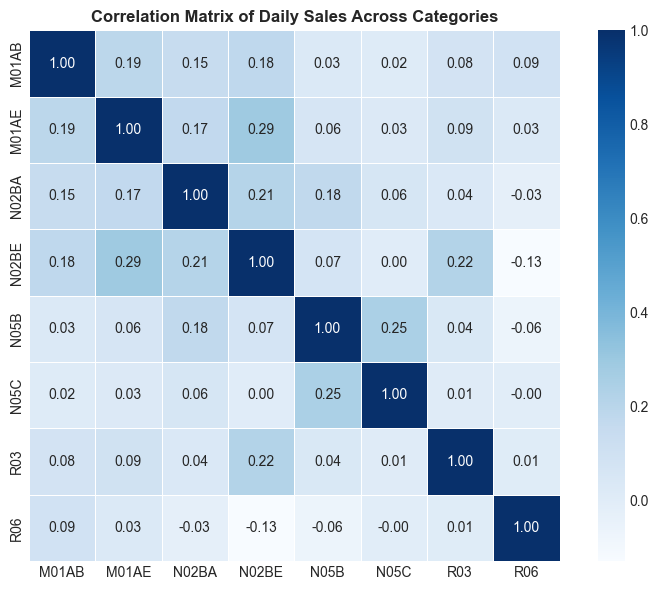

In [7]:
plt.figure(figsize=(8, 6))
corr = df[atc_cols].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='Blues', square=True, linewidths=0.5)
plt.title('Correlation Matrix of Daily Sales Across Categories', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

### 8. Key EDA Findings & Implications
1. **Volume Concentration**: Over 45% of total pharmacy demand is concentrated in `N02BE` (Anilides / Paracetamol), averaging 29.92 units/day with high responsiveness to winter respiratory illness periods.
2. **Continuous Chronic Needs**: `M01AB` (Diclofenac) and `M01AE` (Ibuprofen) show near-constant daily demand (mean 5.03 and 3.90 units/day) with low coefficients of variation and fewer than 2% zero days.
3. **Zero-Day Sparsity**: `N05C` (Hypnotics) exhibits 67.9% zero days, while `R03` exhibits 23.0% zero days. Using MAPE for model evaluation would lead to division by zero; **WAPE** and **MAE** must be used.
4. **Autoregressive Features**: Strong weekly autocorrelation indicates that 1, 7, 14, and 30-day lags and 7/30-day rolling averages will form effective feature representations for XGBoost and Random Forest models.
